In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))
#         break

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session`

In [22]:
import torch
from torch.utils.data import Dataset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [23]:
from torch.utils.data import Dataset, DataLoader, random_split
from pathlib import Path
from torchvision import transforms
import os
from pathlib import Path
from PIL import Image
import pandas as pd

import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

class CustomDataset(Dataset):
    def __init__(self, class_to_label_csv: Path, images_dir: Path, has_labels=True, transform=None):
        self.class_to_label = pd.read_csv(class_to_label_csv)
        self.images_dir = images_dir
        self.images = [file_name for file_name in os.listdir(images_dir)]
        self.transform = transform if transform else transforms.ToTensor()
        self.has_labels = has_labels

        self.classes = sorted(self.class_to_label.iloc[:, 0].unique())
        self.class_to_idx = {row["name"]: row["label"] for idx, row in self.class_to_label.iterrows()}

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        file_name = self.images[idx]
        img_path = os.path.join(self.images_dir, file_name)
        image = Image.open(img_path).convert("RGB")
        image = self.transform(image)

        if self.has_labels:
            cls = file_name.split("_")[0]
            label = self.class_to_idx[cls]
            return image, label
        else:
            return image, file_name

In [24]:
frame = pd.read_csv("class_names.csv")
names_classes = frame['name'].to_list()
names_classes

['panda',
 'bear',
 'lion',
 'deer',
 'tiger',
 'bird',
 'horse',
 'dolphin',
 'elephant',
 'dog',
 'zebra',
 'giraffe',
 'kangaroo',
 'cat']

In [25]:

full_train = CustomDataset(
    class_to_label_csv=Path("class_names.csv"), 
    images_dir=Path("./train/"), 
    has_labels=True
)

In [26]:
print(full_train[0][0].shape)
print('image shape', full_train[0][0].shape)

torch.Size([3, 224, 224])
image shape torch.Size([3, 224, 224])


In [27]:
BATCH_SIZE = 32
trainloader = DataLoader(full_train,shuffle=True,batch_size=BATCH_SIZE)
device = 'cpu'

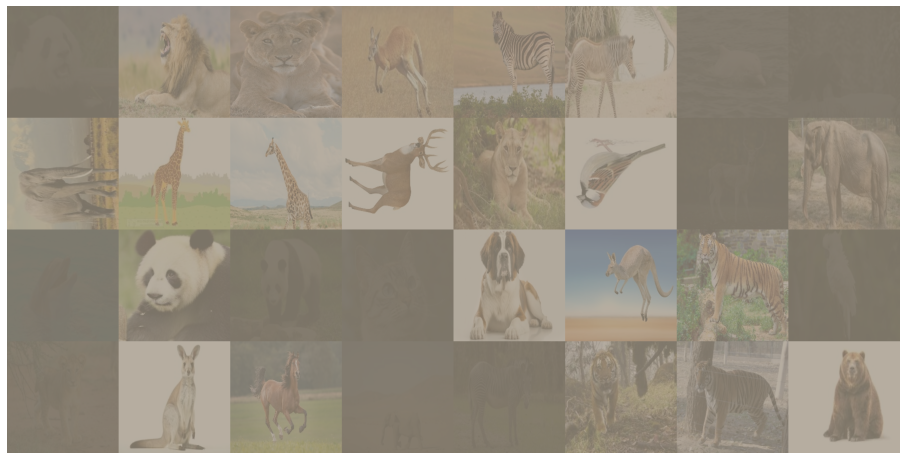

first raw classes panda  lion  lion kangaroo zebra zebra dolphin  bear elephant giraffe giraffe  deer  lion  bird  deer elephant dolphin panda panda   cat   dog kangaroo tiger  bird  lion kangaroo horse elephant zebra tiger tiger  bear
torch.Size([32, 3, 224, 224])


In [28]:
MEAN = torch.tensor([0.485, 0.456, 0.406]) 
STD  = torch.tensor([0.229, 0.224, 0.225])
def imshow(images, nrow = 8,figsize=(16,12), mean=MEAN, std=STD):
    
    img = torchvision.utils.make_grid(images, nrow = nrow, padding = 0).to(device)

    img = img.transpose(2,0).transpose(0,1)

    std = torch.as_tensor(std).to(device)
    mean = torch.as_tensor(mean).to(device)
    img = (img * std + mean)# unnormalize 
    
    img = img.data.cpu().numpy()
       
    plt.figure(figsize=(16,12))
    plt.imshow(img); plt.axis('off'); plt.show()


images, labels = next(iter(trainloader))

imshow(images)

print('first raw classes',' '.join('%5s' % names_classes[labels[j]] for j in range(BATCH_SIZE)))

print(images.shape)